# LAB 09 — Bias, Variance and Imbalanced Data
## Fall 2026 — Machine Learning

## Student Information
**Name:** Abdullah Hussain 
**Student ID:** 023-24-0241  
**Section:** G  
**GitHub:** https://github.com/Abdullah-Hussain-45/Machine_Learning-2026
**Kaggle:** https://www.kaggle.com/abdullahhussain34  

**Dataset:** Stroke Prediction Dataset  
**Dataset Source:** https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset

**Target:** `stroke` (0 = no stroke, 1 = stroke)

---
## Setup

Import the libraries required for the tasks. The code uses the pandas, NumPy, Matplotlib, scikit-learn and imbalanced-learn operations required by the lab manual.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.model_selection import validation_curve, learning_curve, cross_val_predict
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier

from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, confusion_matrix, roc_auc_score
from sklearn.metrics import average_precision_score, roc_curve
from sklearn.metrics import precision_recall_curve

from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler, SMOTE

SEED = 42

---
## 1. Problem Definition & Dataset Exploration

**Concepts/functions:** `pd.read_csv()`, `df.shape`, `df.head()`, `value_counts()`, `isna().sum()`.

**Tasks**
1. Load the stroke dataset and inspect its shape and columns.
2. Report missing values, gender counts, and stroke counts and percentages.
3. Remove the identifier and the very small `Other` gender category.

In [2]:
df = pd.read_csv("healthcare-dataset-stroke-data_1.csv")

print("Dataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

print("\nColumns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isna().sum())

print("\nGender counts:")
print(df["gender"].value_counts())

print("\nStroke counts:")
print(df["stroke"].value_counts())

print("\nStroke percentages:")
print((df["stroke"].value_counts(normalize=True) * 100).round(2))

Dataset shape: (5110, 12)

First five rows:


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1



Columns:
['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'avg_glucose_level', 'bmi', 'smoking_status', 'stroke']

Missing values:
id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

Gender counts:
gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64

Stroke counts:
stroke
0    4861
1     249
Name: count, dtype: int64

Stroke percentages:
stroke
0    95.13
1     4.87
Name: proportion, dtype: float64


**Answer 1 — Dataset exploration**

The dataset contains 5,110 patient records and 12 columns. Each row represents one patient. The target column is `stroke`, where 1 represents a recorded stroke and 0 represents no recorded stroke. The dataset contains 249 stroke cases (4.87%) and 4,861 non-stroke cases (95.13%). The `bmi` column contains 201 missing values. The `gender` category `Other` has only one record, so it is removed as instructed by the lab manual.

In [3]:
# Remove the identifier and the gender category with only one record.
df = df.drop(columns=["id"])
df = df[df["gender"] != "Other"].copy()

print("Shape after cleaning:", df.shape)
print("\nGender counts after cleaning:")
print(df["gender"].value_counts())

Shape after cleaning: (5109, 11)

Gender counts after cleaning:
gender
Female    2994
Male      2115
Name: count, dtype: int64


## 2. Data Preparation: Encoding, Split, Imputation and Scaling

**Concepts/functions:** `pd.get_dummies()`, `train_test_split()`, `SimpleImputer`, `StandardScaler`.

**Tasks**
1. Separate the features and target.
2. Convert categorical columns into numeric indicator columns.
3. Split the data into 80% training and 20% testing using stratification.
4. Fill missing numeric values using the training median only.
5. Create scaled copies for Logistic Regression.

In [4]:
X = df.drop(columns=["stroke"])
y = df["stroke"]

# Convert categorical columns into one-hot encoded columns.
X = pd.get_dummies(X, dtype=int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

# Learn the median from training data only.
imputer = SimpleImputer(strategy="median")

X_train = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

# Fit the scaler on training data only.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("\nTraining target counts:")
print(y_train.value_counts())
print("\nTesting target counts:")
print(y_test.value_counts())

Training shape: (4087, 20)
Testing shape: (1022, 20)

Training target counts:
stroke
0    3888
1     199
Name: count, dtype: int64

Testing target counts:
stroke
0    972
1     50
Name: count, dtype: int64


**Answer 2 — Data preparation**

The `id` column is removed because it identifies a record rather than describing a useful patient characteristic. `gender`, `ever_married`, `work_type`, `Residence_type`, and `smoking_status` are converted using one-hot encoding. `stratify=y` keeps approximately the same stroke proportion in both sets. The median imputer and scaler are fitted only on the training set; the test set is transformed using those already learned values. This prevents information from the test set from influencing preprocessing.

After removing the single `Other` record, there are 5,109 records. The stratified split contains 4,087 training records and 1,022 test records, with 199 and 50 stroke cases respectively.

---
## 3. The Accuracy Trap — Baseline and Logistic Regression

**Concepts/functions:** `DummyClassifier()`, `LogisticRegression()`, `predict()`, `predict_proba()`, accuracy, precision, recall, F1, ROC AUC, average precision and confusion matrix.

**Tasks**
1. Train a majority-class baseline.
2. Train default Logistic Regression on scaled data.
3. Calculate all six required metrics and show the confusion matrix.

In [5]:
# Majority-class baseline
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
dummy_pred = dummy.predict(X_test)

print("Majority baseline accuracy:",
      accuracy_score(y_test, dummy_pred))

# Logistic Regression
lr = LogisticRegression(max_iter=1000, random_state=SEED)
lr.fit(X_train_scaled, y_train)

lr_pred = lr.predict(X_test_scaled)
lr_prob = lr.predict_proba(X_test_scaled)[:, 1]

lr_metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score",
               "ROC AUC", "PR AUC (Average Precision)"],
    "Score": [
        accuracy_score(y_test, lr_pred),
        precision_score(y_test, lr_pred, zero_division=0),
        recall_score(y_test, lr_pred, zero_division=0),
        f1_score(y_test, lr_pred, zero_division=0),
        roc_auc_score(y_test, lr_prob),
        average_precision_score(y_test, lr_prob)
    ]
})
display(lr_metrics)

print("Confusion matrix:")
print(confusion_matrix(y_test, lr_pred))

Majority baseline accuracy: 0.9510763209393346


,Metric,Score
0,Accuracy,0.952055
1,Precision,1.000000
2,Recall,0.020000
3,F1-score,0.039216
4,ROC AUC,0.839300
5,PR AUC (Average Precision),0.269592


Confusion matrix:
[[972   0]
 [ 49   1]]


**Answer 3 — Accuracy trap**

A majority-class classifier can obtain approximately 95% accuracy by predicting every patient as having no stroke. However, it detects no stroke cases, so its recall is zero. Accuracy is misleading because the negative class represents about 95% of the dataset. For a screening problem, recall, precision, F1, ROC AUC, average precision and the confusion matrix provide more useful information. A false negative is a stroke case predicted as no stroke, meaning that the model misses a positive case.

---
## 4. Underfitting, Overfitting, Bias and Variance

### 4.1 Validation Curve

**Concepts/functions:** `DecisionTreeClassifier()`, `StratifiedKFold()`, `validation_curve()`.

The validation curve compares training ROC AUC and cross-validation ROC AUC for different values of `max_depth`. Cross-validation is performed on the training set only.

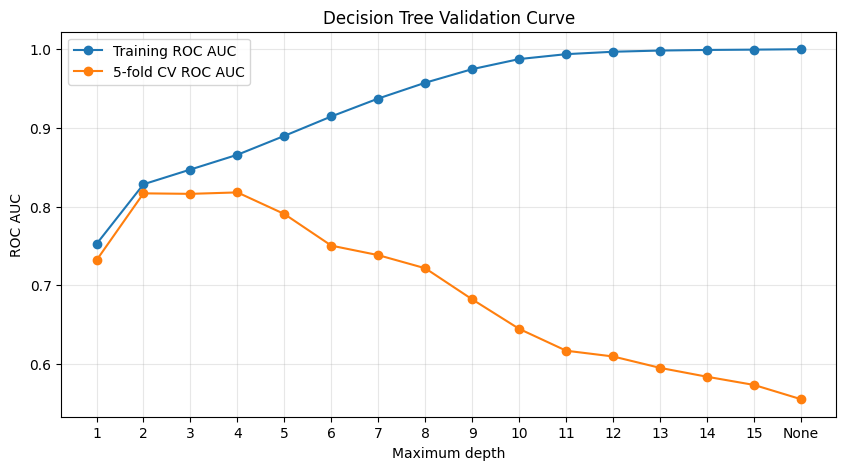

Best depth: 4
Best CV ROC AUC: 0.8179513303806363


In [6]:
depths = list(range(1, 16)) + [None]

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

train_scores, valid_scores = validation_curve(
    DecisionTreeClassifier(random_state=SEED),
    X_train,
    y_train,
    param_name="max_depth",
    param_range=depths,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

train_auc = train_scores.mean(axis=1)
valid_auc = valid_scores.mean(axis=1)

depth_labels = [str(d) for d in depths]

plt.figure(figsize=(10, 5))
plt.plot(depth_labels, train_auc, marker="o", label="Training ROC AUC")
plt.plot(depth_labels, valid_auc, marker="o", label="5-fold CV ROC AUC")
plt.xlabel("Maximum depth")
plt.ylabel("ROC AUC")
plt.title("Decision Tree Validation Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

best_index = np.argmax(valid_auc)
print("Best depth:", depths[best_index])
print("Best CV ROC AUC:", valid_auc[best_index])

**Answer 4.1 — Validation curve interpretation**

A shallow tree may underfit because it cannot represent enough patterns in the data. An unrestricted tree may overfit when its training AUC is much higher than its cross-validation AUC. The depth with the highest mean cross-validation ROC AUC is selected as the best depth in this experiment. The training and validation scores above should be used to identify the underfitting and overfitting regions.

### 4.2 Learning Curves

**Concepts/functions:** `learning_curve()`, training score and cross-validation score.

The learning curves show how performance changes when the amount of training data increases. The manual requires a depth-1 tree and an unrestricted tree.

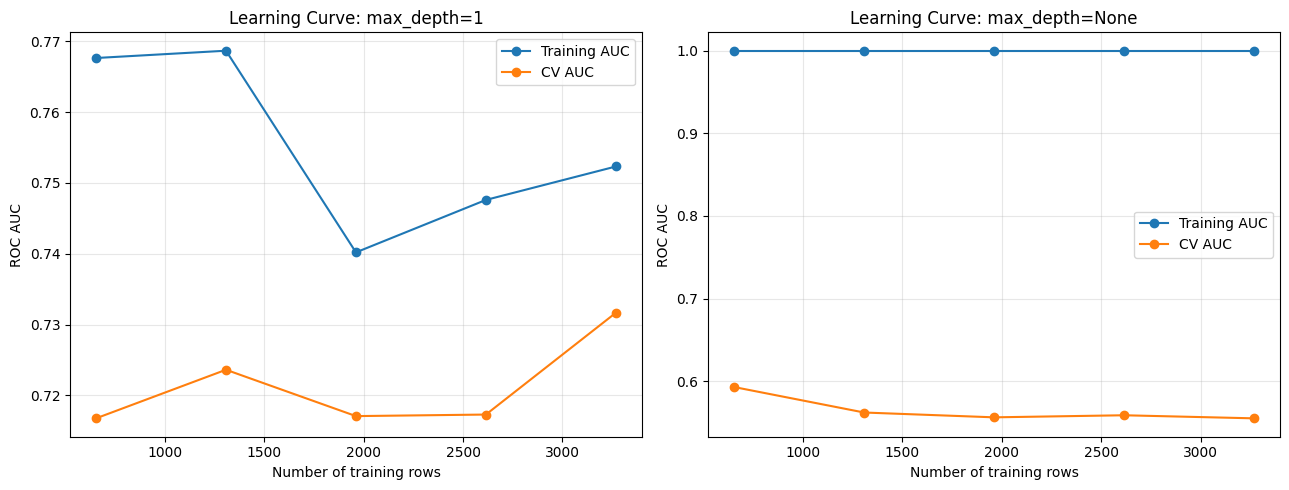

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
training_sizes = np.linspace(0.2, 1.0, 5)

for ax, depth in zip(axes, [1, None]):
    row_counts, train_curve, valid_curve = learning_curve(
        DecisionTreeClassifier(max_depth=depth, random_state=SEED),
        X_train,
        y_train,
        train_sizes=training_sizes,
        cv=cv,
        scoring="roc_auc",
        n_jobs=-1
    )

    ax.plot(row_counts, train_curve.mean(axis=1),
            marker="o", label="Training AUC")
    ax.plot(row_counts, valid_curve.mean(axis=1),
            marker="o", label="CV AUC")
    ax.set_title("Learning Curve: max_depth=" + str(depth))
    ax.set_xlabel("Number of training rows")
    ax.set_ylabel("ROC AUC")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Answer 4.2 — Learning curve interpretation**

High bias is suggested when training and validation scores are both relatively low and close together. High variance is suggested when training performance is high but validation performance is considerably lower. More training data may reduce variance when the validation score improves as additional rows are added. More data alone may not solve high bias; a more suitable model or greater model complexity may be required.

### 4.3 Direct Variance Measurement with Bootstrap Samples

A bootstrap sample is created by randomly selecting training rows with replacement. The lab asks for 40 samples for each tree depth and compares prediction variance and ROC AUC.

In [8]:
rng = np.random.default_rng(SEED)
bootstrap_rows = []

for depth in [1, 3, None]:
    probability_list = []

    for repeat in range(40):
        indexes = rng.choice(
            len(X_train),
            size=len(X_train),
            replace=True
        )

        X_boot = X_train.iloc[indexes]
        y_boot = y_train.iloc[indexes]

        tree = DecisionTreeClassifier(
            max_depth=depth,
            random_state=SEED
        )
        tree.fit(X_boot, y_boot)

        probabilities = tree.predict_proba(X_test)[:, 1]
        probability_list.append(probabilities)

    probability_array = np.array(probability_list)

    patient_variance = probability_array.var(axis=0)
    mean_variance = patient_variance.mean()

    individual_auc = []
    for probabilities in probability_array:
        individual_auc.append(
            roc_auc_score(y_test, probabilities)
        )

    average_probability = probability_array.mean(axis=0)
    average_auc = roc_auc_score(y_test, average_probability)

    bootstrap_rows.append({
        "Max depth": str(depth),
        "Mean prediction variance": mean_variance,
        "Mean individual-tree AUC": np.mean(individual_auc),
        "AUC of averaged predictions": average_auc
    })

bootstrap_table = pd.DataFrame(bootstrap_rows)
display(bootstrap_table.round(4))

,Max depth,Mean prediction variance,Mean individual-tree AUC,AUC of averaged predictions
0,1,0.0007,0.7623,0.8132
1,3,0.0017,0.7963,0.8336
2,None,0.0420,0.5542,0.7701


**Answer 4.3 — Bias-variance trade-off**

Bias is error caused by a model being too simple or making restrictive assumptions. Variance describes how much predictions change when the training sample changes. A depth-1 tree is highly constrained and may have high bias. A depth-3 tree has more flexibility. An unrestricted tree can have higher variance because small changes in training rows may produce different splits. Averaging predictions from multiple trees can reduce variation, which is one principle used by Random Forest.

---
## 5. ROC, Precision-Recall and Decision Thresholds

### 5.1 Compare Logistic Regression, Decision Tree and Random Forest

The models are trained on the original training data. Logistic Regression uses scaled features; tree models use the unscaled imputed features.

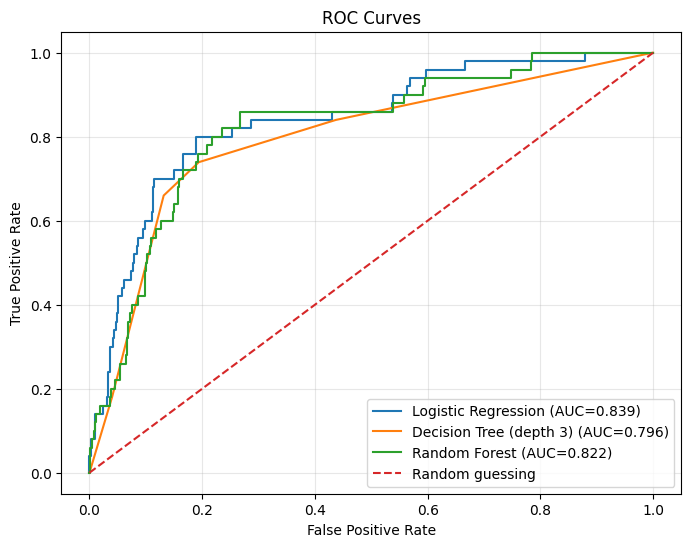

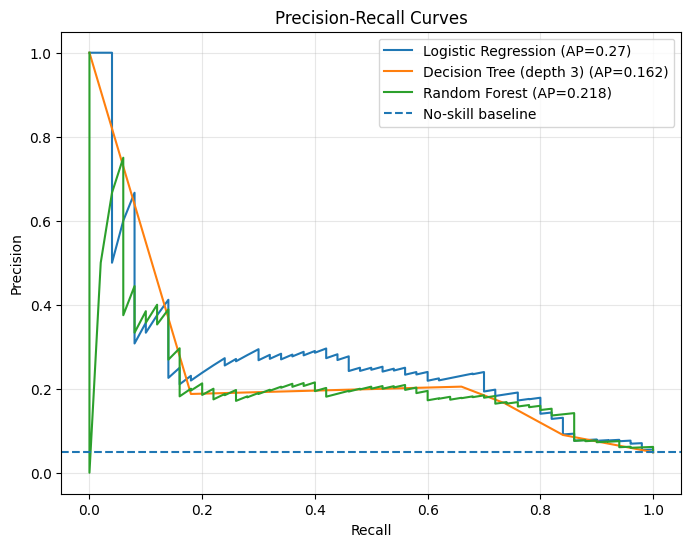

In [9]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, random_state=SEED
    ),
    "Decision Tree (depth 3)": DecisionTreeClassifier(
        max_depth=3, random_state=SEED
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=5,
        random_state=SEED,
        n_jobs=-1
    )
}

model_probabilities = {}

for name, model in models.items():
    if name == "Logistic Regression":
        model.fit(X_train_scaled, y_train)
        model_probabilities[name] = model.predict_proba(X_test_scaled)[:, 1]
    else:
        model.fit(X_train, y_train)
        model_probabilities[name] = model.predict_proba(X_test)[:, 1]

# ROC curves
plt.figure(figsize=(8, 6))
for name, probabilities in model_probabilities.items():
    fpr, tpr, thresholds = roc_curve(y_test, probabilities)
    auc_value = roc_auc_score(y_test, probabilities)
    plt.plot(fpr, tpr, label=name + " (AUC=" + str(round(auc_value, 3)) + ")")

plt.plot([0, 1], [0, 1], "--", label="Random guessing")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Precision-recall curves
plt.figure(figsize=(8, 6))
for name, probabilities in model_probabilities.items():
    precision_values, recall_values, thresholds = precision_recall_curve(
        y_test, probabilities
    )
    ap_value = average_precision_score(y_test, probabilities)
    plt.plot(recall_values, precision_values,
             label=name + " (AP=" + str(round(ap_value, 3)) + ")")

plt.axhline(y=y_test.mean(), linestyle="--",
            label="No-skill baseline")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Answer 5.1 — ROC and PR curves**

ROC AUC measures how well the model ranks positive cases above negative cases across thresholds. Average precision summarizes the precision-recall curve and is especially informative when the positive class is rare. The no-skill precision-recall baseline is the positive-class proportion in the test set. Both curves are useful, but the precision-recall curve directly shows the trade-off between finding stroke cases and generating false alarms.

### 5.2 Select a Threshold for at Least 80% Recall

The threshold is selected using out-of-fold predictions from the training set only. It is then applied once to the test probabilities.

In [10]:
oof_probabilities = cross_val_predict(
    LogisticRegression(max_iter=1000, random_state=SEED),
    X_train_scaled,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

candidate_thresholds = np.sort(np.unique(oof_probabilities))
eligible_thresholds = []

for threshold in candidate_thresholds:
    oof_predictions = (oof_probabilities >= threshold).astype(int)
    current_recall = recall_score(y_train, oof_predictions)

    if current_recall >= 0.80:
        eligible_thresholds.append(threshold)

chosen_threshold = max(eligible_thresholds)
print("Chosen threshold:", chosen_threshold)

# Fit Logistic Regression on all training rows.
threshold_model = LogisticRegression(max_iter=1000, random_state=SEED)
threshold_model.fit(X_train_scaled, y_train)

threshold_test_prob = threshold_model.predict_proba(X_test_scaled)[:, 1]
threshold_test_pred = (threshold_test_prob >= chosen_threshold).astype(int)

print("Test recall:", recall_score(y_test, threshold_test_pred))
print("Test precision:", precision_score(
    y_test, threshold_test_pred, zero_division=0
))
print("Confusion matrix:")
print(confusion_matrix(y_test, threshold_test_pred))
print("Patients flagged:", int(threshold_test_pred.sum()))
print("False alarms:", int(((threshold_test_pred == 1) & (y_test == 0)).sum()))

Chosen threshold: 0.05068335052237635
Test recall: 0.82
Test precision: 0.13442622950819672
Confusion matrix:
[[708 264]
 [  9  41]]
Patients flagged: 305
False alarms: 264


**Answer 5.2 — Threshold interpretation**

A model can have a strong ROC AUC but low recall at the default 0.5 threshold because ROC AUC evaluates ranking across all thresholds, whereas recall at 0.5 evaluates only one operating point. Lowering the threshold generally flags more patients and can increase recall, but it also tends to increase false positives and reduce precision. The threshold is selected from training out-of-fold predictions to avoid using the test labels for model decisions. The final test recall may differ from 80%, because the test set contains only 50 stroke cases.

---
## 6. Undersampling, Oversampling and SMOTE

### 6.1 Compare five methods

The methods are: no resampling, class weighting, random undersampling, random oversampling and SMOTE. Resampling is performed on the training set only. The test set remains unchanged.

In [11]:
comparison_rows = []

for model_name in ["Logistic Regression", "Random Forest"]:
    for method in ["No resampling", "Class weight", "Undersampling",
                   "Oversampling", "SMOTE"]:

        if model_name == "Logistic Regression":
            X_original_train = X_train_scaled
            X_original_test = X_test_scaled
        else:
            X_original_train = X_train
            X_original_test = X_test

        y_original_train = y_train.copy()

        if method == "Undersampling":
            sampler = RandomUnderSampler(random_state=SEED)
            X_fit, y_fit = sampler.fit_resample(
                X_original_train, y_original_train
            )
        elif method == "Oversampling":
            sampler = RandomOverSampler(random_state=SEED)
            X_fit, y_fit = sampler.fit_resample(
                X_original_train, y_original_train
            )
        elif method == "SMOTE":
            sampler = SMOTE(random_state=SEED)
            X_fit, y_fit = sampler.fit_resample(
                X_original_train, y_original_train
            )
        else:
            X_fit, y_fit = X_original_train, y_original_train

        if model_name == "Logistic Regression":
            if method == "Class weight":
                model = LogisticRegression(
                    max_iter=1000, class_weight="balanced",
                    random_state=SEED
                )
            else:
                model = LogisticRegression(
                    max_iter=1000, random_state=SEED
                )
        else:
            if method == "Class weight":
                model = RandomForestClassifier(
                    n_estimators=200, min_samples_leaf=5,
                    class_weight="balanced", random_state=SEED,
                    n_jobs=-1
                )
            else:
                model = RandomForestClassifier(
                    n_estimators=200, min_samples_leaf=5,
                    random_state=SEED, n_jobs=-1
                )

        model.fit(X_fit, y_fit)
        prediction = model.predict(X_original_test)
        probability = model.predict_proba(X_original_test)[:, 1]

        comparison_rows.append({
            "Model": model_name,
            "Method": method,
            "Training rows": len(y_fit),
            "Training strokes": int((np.array(y_fit) == 1).sum()),
            "Precision": precision_score(y_test, prediction, zero_division=0),
            "Recall": recall_score(y_test, prediction, zero_division=0),
            "F1": f1_score(y_test, prediction, zero_division=0),
            "ROC AUC": roc_auc_score(y_test, probability),
            "PR AUC": average_precision_score(y_test, probability)
        })

resampling_table = pd.DataFrame(comparison_rows)
display(resampling_table.round(4))

,Model,Method,Training rows,Training strokes,Precision,Recall,F1,ROC AUC,PR AUC
0,Logistic Regression,No resampling,4087,199,1.0000,0.02,0.0392,0.8393,0.2696
1,Logistic Regression,Class weight,4087,199,0.1347,0.80,0.2305,0.8396,0.2596
2,Logistic Regression,Undersampling,398,199,0.1246,0.82,0.2164,0.8350,0.2333
3,Logistic Regression,Oversampling,7776,3888,0.1333,0.80,0.2286,0.8385,0.2591
4,Logistic Regression,SMOTE,7776,3888,0.1347,0.80,0.2305,0.8407,0.2957
5,Random Forest,No resampling,4087,199,0.0000,0.00,0.0000,0.8215,0.2183
6,Random Forest,Class weight,4087,199,0.1667,0.20,0.1818,0.8061,0.2045
7,Random Forest,Undersampling,398,199,0.1032,0.84,0.1838,0.8132,0.1972
8,Random Forest,Oversampling,7776,3888,0.1412,0.24,0.1778,0.8023,0.1837
9,Random Forest,SMOTE,7776,3888,0.6667,0.04,0.0755,0.8046,0.2424


**Answer 6.1 — Resampling comparison**

Resampling changes the training data distribution, while class weighting changes the penalty assigned to class errors. Undersampling removes majority-class records and may discard useful information. Oversampling duplicates minority-class records and may increase overfitting. SMOTE creates synthetic minority examples between neighboring minority examples. The best method is determined by comparing test precision, recall, F1, ROC AUC and average precision while considering the number of training rows.

### 6.2 Demonstrate the Incorrect SMOTE Order (Data Leakage)

The following experiment is intentionally incorrect. SMOTE is applied to all records before splitting. It is included only to demonstrate why this order must not be used for a valid evaluation.

In [14]:
# WRONG ORDER — demonstration only; do not use this result as a valid score.

# Step 1: Handle missing values before applying SMOTE.
X_all_filled = X.copy()

X_all_filled["bmi"] = X_all_filled["bmi"].fillna(
    X_all_filled["bmi"].median()
)

# Step 2: Apply SMOTE before splitting (incorrect order).
X_all_smote, y_all_smote = SMOTE(random_state=SEED).fit_resample(
    X_all_filled, y
)

# Step 3: Split the already-resampled dataset.
X_wrong_train, X_wrong_test, y_wrong_train, y_wrong_test = train_test_split(
    X_all_smote,
    y_all_smote,
    test_size=0.20,
    random_state=SEED,
    stratify=y_all_smote
)

# Step 4: Train the model.
wrong_model = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=5,
    random_state=SEED,
    n_jobs=-1
)

wrong_model.fit(X_wrong_train, y_wrong_train)

wrong_probability = wrong_model.predict_proba(X_wrong_test)[:, 1]
wrong_prediction = wrong_model.predict(X_wrong_test)


# CORRECT ORDER — split first, then apply SMOTE only to training data.

correct_sampler = SMOTE(random_state=SEED)

X_correct_smote, y_correct_smote = correct_sampler.fit_resample(
    X_train, y_train
)

correct_model = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=5,
    random_state=SEED,
    n_jobs=-1
)

correct_model.fit(X_correct_smote, y_correct_smote)

correct_probability = correct_model.predict_proba(X_test)[:, 1]
correct_prediction = correct_model.predict(X_test)


# Step 5: Compare both approaches.

wrong_correct_table = pd.DataFrame({
    "Method": [
        "Correct: split then SMOTE",
        "Wrong: SMOTE then split"
    ],
    "Accuracy": [
        accuracy_score(y_test, correct_prediction),
        accuracy_score(y_wrong_test, wrong_prediction)
    ],
    "Precision": [
        precision_score(y_test, correct_prediction, zero_division=0),
        precision_score(y_wrong_test, wrong_prediction, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, correct_prediction, zero_division=0),
        recall_score(y_wrong_test, wrong_prediction, zero_division=0)
    ],
    "ROC AUC": [
        roc_auc_score(y_test, correct_probability),
        roc_auc_score(y_wrong_test, wrong_probability)
    ],
    "PR AUC": [
        average_precision_score(y_test, correct_probability),
        average_precision_score(y_wrong_test, wrong_probability)
    ]
})

display(wrong_correct_table.round(4))

,Method,Accuracy,Precision,Recall,ROC AUC,PR AUC
0,Correct: split then SMOTE,0.9521,0.6667,0.0400,0.8046,0.2424
1,Wrong: SMOTE then split,0.9712,0.9893,0.9527,0.9950,0.9957


**Answer 6.2 — Why the wrong-order result cannot be trusted**

When SMOTE is applied before splitting, the synthetic examples are created using the full dataset, including records that later become part of the test set. Related or highly similar information can therefore occur in both training and testing data. The test set is also artificially balanced and no longer represents the original patient distribution. The resulting metrics can be overly optimistic and are not a valid estimate of performance on unseen patients.

---
## 7. Noisy Data

### 7.1 Label Noise

Label noise means that some training target labels are incorrect. The experiment randomly flips 0 to 1 and 1 to 0 in the training labels only. The original test labels remain unchanged.

Model,Decision Tree (depth 3),Decision Tree (unlimited),Logistic Regression,Random Forest
Noise,,,,
0.00,0.7956,0.5722,0.8393,0.8215
0.05,0.8084,0.5491,0.8232,0.7764
0.10,0.7928,0.5289,0.8112,0.7757
0.20,0.7499,0.5199,0.8022,0.6971


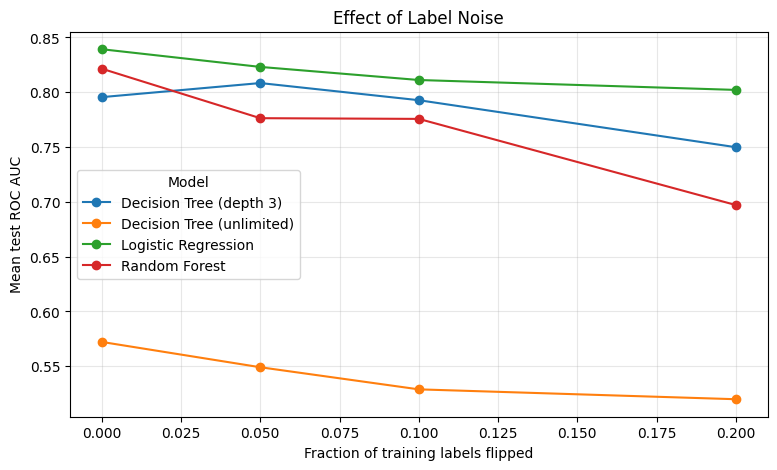

In [15]:
noise_levels = [0, 0.05, 0.10, 0.20]
noise_model_names = [
    "Logistic Regression",
    "Decision Tree (depth 3)",
    "Decision Tree (unlimited)",
    "Random Forest"
]

label_noise_rows = []

for noise_level in noise_levels:
    repeats = 1 if noise_level == 0 else 5

    for repeat in range(repeats):
        rng = np.random.default_rng(
            SEED + int(noise_level * 1000) + repeat
        )
        y_noisy = y_train.to_numpy().copy()

        number_to_flip = int(round(noise_level * len(y_noisy)))
        if number_to_flip > 0:
            flip_indexes = rng.choice(
                len(y_noisy), number_to_flip, replace=False
            )
            y_noisy[flip_indexes] = 1 - y_noisy[flip_indexes]

        for model_name in noise_model_names:
            if model_name == "Logistic Regression":
                model = LogisticRegression(max_iter=1000, random_state=SEED)
                X_fit, X_eval = X_train_scaled, X_test_scaled
            elif model_name == "Decision Tree (depth 3)":
                model = DecisionTreeClassifier(max_depth=3, random_state=SEED)
                X_fit, X_eval = X_train, X_test
            elif model_name == "Decision Tree (unlimited)":
                model = DecisionTreeClassifier(random_state=SEED)
                X_fit, X_eval = X_train, X_test
            else:
                model = RandomForestClassifier(
                    n_estimators=200, min_samples_leaf=5,
                    random_state=SEED, n_jobs=-1
                )
                X_fit, X_eval = X_train, X_test

            model.fit(X_fit, y_noisy)
            probability = model.predict_proba(X_eval)[:, 1]

            label_noise_rows.append({
                "Noise": noise_level,
                "Repeat": repeat,
                "Model": model_name,
                "ROC AUC": roc_auc_score(y_test, probability)
            })

label_noise_results = pd.DataFrame(label_noise_rows)
label_noise_summary = label_noise_results.groupby(
    ["Noise", "Model"]
)["ROC AUC"].mean().unstack()

display(label_noise_summary.round(4))

label_noise_summary.plot(marker="o", figsize=(9, 5))
plt.xlabel("Fraction of training labels flipped")
plt.ylabel("Mean test ROC AUC")
plt.title("Effect of Label Noise")
plt.grid(alpha=0.3)
plt.show()

**Answer 7.1 — Label noise interpretation**

Label noise gives the model incorrect target information during training. A model may learn misleading relationships because some records are assigned the wrong class. Flexible models, particularly unrestricted trees, can be sensitive to such errors because they can form specific splits around individual observations. The table and plot show how each model's test ROC AUC changes as the percentage of flipped training labels increases.

### 7.2 Feature Noise

Feature noise adds Gaussian random values to `age`, `avg_glucose_level`, and `bmi` in the training data. The test data and target labels are not changed.

Model,Decision Tree (depth 3),Decision Tree (unlimited),Logistic Regression,Random Forest
Noise,,,,
0.0,0.7956,0.5722,0.8393,0.8215
0.5,0.7985,0.5272,0.8333,0.8075
1.0,0.7773,0.5392,0.8126,0.7839
2.0,0.7149,0.5166,0.7686,0.7181


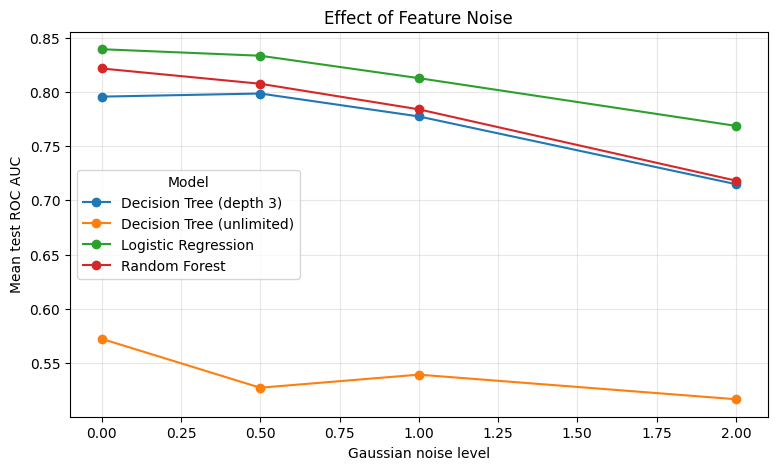

In [16]:
numeric_features = ["age", "avg_glucose_level", "bmi"]
feature_noise_levels = [0, 0.5, 1, 2]
feature_noise_rows = []

for noise_level in feature_noise_levels:
    repeats = 1 if noise_level == 0 else 5

    for repeat in range(repeats):
        rng = np.random.default_rng(
            SEED + int(noise_level * 100) + repeat
        )
        X_noisy = X_train.copy()

        for column in numeric_features:
            column_std = X_train[column].std()
            added_noise = rng.normal(
                0,
                noise_level * column_std,
                len(X_train)
            )
            X_noisy[column] = X_noisy[column] + added_noise

        # Refit scaling on this noisy training set.
        noisy_scaler = StandardScaler()
        X_noisy_scaled = noisy_scaler.fit_transform(X_noisy)
        X_test_scaled_for_noise = noisy_scaler.transform(X_test)

        for model_name in noise_model_names:
            if model_name == "Logistic Regression":
                model = LogisticRegression(max_iter=1000, random_state=SEED)
                X_fit, X_eval = X_noisy_scaled, X_test_scaled_for_noise
            elif model_name == "Decision Tree (depth 3)":
                model = DecisionTreeClassifier(max_depth=3, random_state=SEED)
                X_fit, X_eval = X_noisy, X_test
            elif model_name == "Decision Tree (unlimited)":
                model = DecisionTreeClassifier(random_state=SEED)
                X_fit, X_eval = X_noisy, X_test
            else:
                model = RandomForestClassifier(
                    n_estimators=200, min_samples_leaf=5,
                    random_state=SEED, n_jobs=-1
                )
                X_fit, X_eval = X_noisy, X_test

            model.fit(X_fit, y_train)
            probability = model.predict_proba(X_eval)[:, 1]

            feature_noise_rows.append({
                "Noise": noise_level,
                "Repeat": repeat,
                "Model": model_name,
                "ROC AUC": roc_auc_score(y_test, probability)
            })

feature_noise_results = pd.DataFrame(feature_noise_rows)
feature_noise_summary = feature_noise_results.groupby(
    ["Noise", "Model"]
)["ROC AUC"].mean().unstack()

display(feature_noise_summary.round(4))

feature_noise_summary.plot(marker="o", figsize=(9, 5))
plt.xlabel("Gaussian noise level")
plt.ylabel("Mean test ROC AUC")
plt.title("Effect of Feature Noise")
plt.grid(alpha=0.3)
plt.show()

**Answer 7.2 — Feature noise interpretation**

Feature noise changes the input measurements but leaves the correct target labels unchanged. As the noise level increases, useful information in the selected numerical features may become less clear. The effect can differ between Logistic Regression, shallow trees, unrestricted trees and Random Forest because they learn patterns differently. The measured results should be used to identify which model is most stable in this experiment.

### 7.3 SMOTE with Noisy Labels

Flip 10% of training labels using three different random draws. Compare Logistic Regression and Random Forest with and without SMOTE. SMOTE is applied after label noise is added.

In [17]:
smote_noise_rows = []

for repeat in range(3):
    rng = np.random.default_rng(SEED + 500 + repeat)
    y_noisy = y_train.to_numpy().copy()

    number_to_flip = int(round(0.10 * len(y_noisy)))
    flip_indexes = rng.choice(
        len(y_noisy), number_to_flip, replace=False
    )
    y_noisy[flip_indexes] = 1 - y_noisy[flip_indexes]

    for model_name in ["Logistic Regression", "Random Forest"]:
        if model_name == "Logistic Regression":
            X_original = X_train_scaled
            X_evaluation = X_test_scaled
        else:
            X_original = X_train
            X_evaluation = X_test

        for use_smote in [False, True]:
            if use_smote:
                sampler = SMOTE(random_state=SEED + repeat)
                X_fit, y_fit = sampler.fit_resample(X_original, y_noisy)
            else:
                X_fit, y_fit = X_original, y_noisy

            if model_name == "Logistic Regression":
                model = LogisticRegression(max_iter=1000, random_state=SEED)
            else:
                model = RandomForestClassifier(
                    n_estimators=200, min_samples_leaf=5,
                    random_state=SEED, n_jobs=-1
                )

            model.fit(X_fit, y_fit)
            probability = model.predict_proba(X_evaluation)[:, 1]

            smote_noise_rows.append({
                "Repeat": repeat,
                "Model": model_name,
                "SMOTE": str(use_smote),
                "ROC AUC": roc_auc_score(y_test, probability),
                "PR AUC": average_precision_score(y_test, probability)
            })

smote_noise_results = pd.DataFrame(smote_noise_rows)
display(
    smote_noise_results.groupby(["Model", "SMOTE"])[
        ["ROC AUC", "PR AUC"]
    ].mean().round(4)
)

ROC AUC  PR AUC
Model               SMOTE                 
Logistic Regression False   0.8268  0.2830
                    True    0.8137  0.2715
Random Forest       False   0.7525  0.1678
                    True    0.6897  0.1267

**Answer 7.3 — SMOTE and noisy labels**

SMOTE assumes that the minority-class labels supplied to it are correct. If a minority example has an incorrect label, SMOTE may use it when generating additional synthetic minority examples. This can spread the influence of incorrect labels through the training data. The comparison of ROC AUC and PR AUC with and without SMOTE shows whether this effect is harmful for each model in the experiment.

---
## 8. Final Decision and Conclusion

### 8.1 Final model comparison

Compare the default threshold of 0.5 with the threshold selected using training out-of-fold predictions. The following table reports precision, recall, F1, false alarms and missed stroke cases.

In [18]:
# Use the Logistic Regression threshold model trained on the full training set.
default_predictions = (threshold_test_prob >= 0.5).astype(int)
selected_predictions = (threshold_test_prob >= chosen_threshold).astype(int)

default_cm = confusion_matrix(y_test, default_predictions, labels=[0, 1])
selected_cm = confusion_matrix(y_test, selected_predictions, labels=[0, 1])

final_table = pd.DataFrame({
    "Metric": ["Precision", "Recall", "F1", "False alarms", "Missed strokes"],
    "Default threshold 0.5": [
        precision_score(y_test, default_predictions, zero_division=0),
        recall_score(y_test, default_predictions, zero_division=0),
        f1_score(y_test, default_predictions, zero_division=0),
        default_cm[0, 1],
        default_cm[1, 0]
    ],
    "Selected threshold": [
        precision_score(y_test, selected_predictions, zero_division=0),
        recall_score(y_test, selected_predictions, zero_division=0),
        f1_score(y_test, selected_predictions, zero_division=0),
        selected_cm[0, 1],
        selected_cm[1, 0]
    ]
})
display(final_table.round(4))

,Metric,Default threshold 0.5,Selected threshold
0,Precision,1.0000,0.1344
1,Recall,0.0200,0.8200
2,F1,0.0392,0.2310
3,False alarms,0.0000,264.0000
4,Missed strokes,49.0000,9.0000


**Answer 8.1 — Final decision**

For a screening objective, recall is important because false negatives represent stroke cases missed by the model. The selected threshold is based on training out-of-fold predictions, not the test labels. The final choice should be judged using the test precision, recall, F1, false alarms and missed strokes shown above. A higher recall can require more follow-up assessments because the number of false alarms may increase.

### 8.2 Executive Summary

Complete the summary using the values produced by the notebook.

The objective was to evaluate machine-learning methods for stroke classification using an imbalanced dataset. After removing the single-record gender category, the dataset contained 5,109 records, and stroke cases represented approximately 4.87% of the data. The selected approach was **[model and method]**, using a threshold of **[threshold]**. On the untouched test set, it achieved **[precision] precision** and **[recall] recall**, with **[number] false alarms** and **[number] missed stroke cases**. Preprocessing, resampling and threshold selection used training data only to prevent data leakage. One limitation is that the test set contains only 50 stroke cases, so one additional detected or missed case changes recall by two percentage points. Independent clinical validation would be necessary before real-world use.

### 8.3 Final Reflection

**(a) What was the most surprising result in this lab?**

The most important observation is that a model can achieve high accuracy while missing almost all positive cases. This demonstrates why accuracy alone is not sufficient for an imbalanced medical classification problem.

**(b) If you had one more hour, what would you try next?**

I would test additional decision thresholds using training-only validation, compare the stability of the selected model across different data splits, and investigate whether the model's predicted probabilities are well calibrated. I would also seek independent data for further evaluation.